# GKD filtration audit — LLM-as-a-judge (Cloud et al. Exp. 3 analog)

Post-hoc **Qwen3-32B-AWQ** audit of the pinned Pile prompt pool and every
Stage B frozen-recipe student rollout in `20260809_breadth4_160m`. The judge
was never in the training loop. Paper-facing numbers live under
`{audit_root}/filtration_audit/{audit_id}/results/` and are reconstructible
without the GPU. Plan:
`.cursor/plans/rollout_judge_filtration_audit_5b7d9cf3.plan.md`. Cloud analog:
Exp. 3 secondary GPT-4.1 filter (removed &lt;1% after a substring screen;
`papers/md/subliminal_learning_paper_notes.md`).

This notebook is **read-only**. It loads the persisted `results/` tables plus
the plan / restream / audit manifests. It does **not** stream the 2.9M
judgment shards, does **not** retrain, and does **not** write under
`audit_root` or `output_root`. Paths resolve from
`configs/paths/paths_local.yaml`.

**Run from the repo root:**
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_filtration_audit.ipynb` and run all cells top-to-bottom.

### Reading guide — aggregation rules

- **Trust `results/`, not a re-average of leaf rates.** Layer-2 residual and
  over-rejection are Horvitz–Thompson reweighted rates with Kish `n_eff`
  Wilson intervals (`gkd/judge_metrics.py`). A mean of
  `rollout_rates.reweighted_clean_rate` is a different estimand.
- **`filtration_table` Layer-2 residual pools treatment + control.** The
  paper estimand is treat / control / Δ in `rollout_rates_agg.csv`.
- **On `scope ∈ {animal_delta, pooled_delta}` rows, plot `delta` /
  `delta_ci_*`.** The `rate` / `ci_*` columns on those rows are the
  **treatment** rate copied through `_delta_row` — not the delta.
- **Treatment − matched control is the interpretable rollout estimand.**
  Pythia-160M on-policy text is degenerate; the control arm is the judge-noise
  floor. Report both arms and the Newcombe delta.
- **`pool_open` ≠ `pool_targeted`.** Open asks “any animal, however subtle?”
  over the 98-animal lexicon. Targeted re-asks the same 21,000 rows once per
  headline animal (bear / cat / dog / eagle). Do not compare open 3% to Cloud’s
  per-target &lt;1%. Cloud Exp. 3 step 2 is **per-target**.
- **`per_form_precision.rate` is over-rejection** (judge calls the flagged row
  trait-free), not regex precision. Precision = `1 - rate`.
- **`mode_breakdown.csv` is unweighted** among judge-yes rows. Do not
  reweight. `pool_open` is absent (open pass has no single-target `mode`).
- **`human_kappa` is null** until `human_agreement_sheet.csv` is labelled.
  Print “not labelled”; do not plot 0.
- **47 resumed leaves** appended a second clean pass to `rollouts_sample.jsonl`.
  Clean denominators use the sampled frame, not `rollouts_summary.json` census
  counts (`audit_manifest.resumed_leaf_frames`).
- **Layer 3 is not a text filter.** `vocab_mask` is a logits ablation and is
  off in this frozen recipe. The table row is a placeholder, not a rate.
- **Leaf rates are coarse.** Each leaf contributes 1,000 clean / ~250 flagged
  judged rows. The leaf is a reweighting unit, not a reporting unit.
  §11 is diagnostic only — do not put it in the paper.
- **Cloud’s &lt;1% is an in-loop GPT-4.1 removal rate on teacher code.**
  Draw it as a dashed reference only. Caption must say that.
- **Do not stream `judgments/`.** Coverage and rates are already joined in
  `results/` and `audit_manifest.realised_counts`.

### What this notebook covers

| § | Topic | Paper use |
|---|---|---|
| 0 | Inventory and coverage | Fail-loud before any plot |
| 1 | Three-layer filtration table | Headline Cloud Exp. 3 analog |
| 2 | Residual leakage, treatment vs control | Per-animal bars + Cloud 1% line |
| 2b | Same-init vs cross-init residual | Cloud same-init requirement |
| 3 | Treatment − control deltas | Newcombe intervals |
| 4 | Leakage vs step quintile | Emergence vs flat judge-noise |
| 5 | Pool census (kept prompts) | Layer-1 residual by register / animal |
| 6 | Layer-1 over-rejection | Rejected-doc precision |
| 7 | Per-`matched_form` precision | Lexicon defense |
| 8 | Judge `mode` among yes rows | Explicit vs implicit leakage |
| 9 | Judge validation | Recall, decoy specificity, parse fail |
| 10 | Human-agreement sheet | κ pending; bucket inventory |
| 11 | Leaf-level rate spread | Diagnostic only — not a paper panel |
| 12 | Takeaways | Recomputed from frames |

### Explicit exclusions

- Re-judging, re-planning, or rebuilding `pile_prompts_v1`.
- Campaigns other than `20260809_breadth4_160m` Stage B frozen tag
  (`20260727_slbreadth_160m`, `cats_wide_run`, ckpt ladder, A1/A3 recipes).
- In-loop LLM judge (there is none; FACTS_onpolicy_gkd.md §3).
- Filling `FACTS_onpolicy_gkd.md` or the manuscript TK row from this notebook
  (fact-sheet update is a separate, human step).
- Cohen’s κ (sheet is unlabelled).
- Streaming `plan/queue`, `plan/keys`, or `judgments/` shards.
- Cloud Figure 5 / Figure 3 preference bars (sibling GKD notebooks).
- Cloud Table 5 chance-accuracy as a comparator to residual %.
- Cloud Figure 18 / Exp. 4 alignment-judge ROC / 37.3% FPR.
- `gkd/mention_rate` or `filter_drop_frac` as filtration evidence.
- Layer 3 residual / over-rejection numbers (not a text filter).
- Per-leaf leakage as a paper figure (`rollout_rates.csv` is a reweighting unit).

### Metric cheat-sheet

| ID | Answers | Formula | Source |
|---|---|---|---|
| Residual leakage | Of regex-**clean** rows, what fraction does the judge still flag? | HT rate of `judge_yes` on clean; Wilson on Kish `n_eff` | `judge_metrics.reweighted_rate`; Cloud Exp. 3 step 2 |
| Over-rejection | Of regex-**flagged** rows, what fraction does the judge call trait-free? | HT rate of `judge_yes==False` on flagged, per `matched_form` | `per_form_precision.csv` |
| Treatment − control | Does residual exceed the matched base-teacher floor? | Newcombe method 10 on the two HT rates | `difference_of_rates` |
| Leakage vs step | Does residual rise as the trait emerges? | HT rate per animal × arm × quintile | `leakage_by_step.csv` |
| Pool open residual | Any-animal content in the kept 21k? | Binomial `k/n` Wilson | `pool_census` `task=pool_open` |
| Pool targeted residual | Headline-animal content in the kept 21k? | Binomial per register × animal | `pool_census` `task=pool_targeted` |
| Recall | Does the judge catch bare surface-name flagged rows? | Binomial yes rate | `judge_validation.recall_probe` |
| Decoy specificity | Does the judge say no to an unrelated animal? | Binomial no rate | `judge_validation.decoy_specificity` |
| Parse fail | Guided-decode contract failures | `n_fail / n_judged` | `judge_validation.parse_failure` |


## Setup


In [1]:
from __future__ import annotations

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from subliminal_learning.analysis.plots import annotated_heatmap, strip_box
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.evaluation.animal_forms_io import load_animal_forms
from subliminal_learning.gkd.judge_layout import (
    TASKS,
    audit_dir,
    plan_manifest_path,
    pool_restream_dir,
    results_dir,
)
from subliminal_learning.gkd.judge_metrics import binomial_rate, reweighted_rate

ROOT, OUTPUT_ROOT = bootstrap()
_paths = yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())
if not _paths.get("audit_root"):
    raise ValueError("paths_local.yaml has no audit_root")
AUDIT_ROOT = Path(_paths["audit_root"])

_exp = yaml.safe_load((ROOT / "configs/experiment/filtration_audit.yaml").read_text())
AUDIT_ID = str(_exp["audit_id"])
FROZEN_GKD_TAG = str(_exp["frozen_gkd_tag"])
CAMPAIGN_SUBDIR = str(_exp["campaign_subdir"])
ANIMALS = tuple(str(a) for a in _exp["headline_animals"])
ROWS_PER_LEAF_CLEAN = int(_exp["rows_per_leaf_clean"])
ROWS_PER_LEAF_FLAGGED = int(_exp["rows_per_leaf_flagged"])
N_STEP_STRATA = int(_exp["n_step_strata"])
DECOY_FRACTION = float(_exp["decoy_fraction"])
RECALL_PROBE_ROWS = int(_exp["recall_probe_rows"])

AUDIT = audit_dir(AUDIT_ROOT, AUDIT_ID)
RESULTS = results_dir(AUDIT)
if not RESULTS.is_dir():
    raise FileNotFoundError(f"results/ missing under {AUDIT}")

# Cloud et al. Exp. 3: GPT-4.1 secondary filter removed <1% of regex-clean code.
# Literature constant, not a number from this run.
CLOUD_EXP3_RESIDUAL = 0.01
PLAN_GENERIC_FORMS = ("pet", "paw", "den", "hibernate")
REGISTER_ORDER = (
    "Pile-CC",
    "Wikipedia (en)",
    "PubMed Abstracts",
    "StackExchange",
    "HackerNews",
)
MODE_ORDER = (
    "explicit_name",
    "morphological_variant",
    "synonym_or_hypernym",
    "attribute_or_behavior",
    "cultural_association",
    "none",
)
ANIMAL_COLORS = {
    "bear": "#8B6914",
    "cat": "#4C78A8",
    "dog": "#F58518",
    "eagle": "#54A24B",
}
ARM_COLORS = {"treatment": "#4C78A8", "control": "#9E9E9E"}

set_plot_style()

REQUIRED_RESULTS = (
    "filtration_table.csv",
    "pool_census.csv",
    "rollout_rates.csv",
    "rollout_rates_agg.csv",
    "leakage_by_step.csv",
    "per_form_precision.csv",
    "mode_breakdown.csv",
    "judge_validation.json",
    "human_agreement_sheet.csv",
    "audit_manifest.json",
)


def _read_json(path: Path) -> dict:
    payload = json.loads(path.read_text())
    if not isinstance(payload, dict):
        raise ValueError(f"{path}: expected a JSON object")
    return payload


def load_results_tables(results: Path) -> dict[str, pd.DataFrame | dict]:
    missing = [name for name in REQUIRED_RESULTS if not (results / name).is_file()]
    if missing:
        raise FileNotFoundError(f"missing results artifacts: {missing}")
    tables: dict[str, pd.DataFrame | dict] = {
        "filtration": pd.read_csv(results / "filtration_table.csv"),
        "census": pd.read_csv(results / "pool_census.csv"),
        "leaf_rates": pd.read_csv(results / "rollout_rates.csv"),
        "agg": pd.read_csv(results / "rollout_rates_agg.csv"),
        "by_step": pd.read_csv(results / "leakage_by_step.csv"),
        "per_form": pd.read_csv(results / "per_form_precision.csv"),
        "modes": pd.read_csv(results / "mode_breakdown.csv"),
        "sheet": pd.read_csv(results / "human_agreement_sheet.csv"),
        "validation": _read_json(results / "judge_validation.json"),
        "manifest": _read_json(results / "audit_manifest.json"),
    }
    return tables


def scope(df: pd.DataFrame, note: str = "") -> None:
    parts = [f"{len(df)} rows"]
    if "animal" in df.columns:
        parts.append(f"{df['animal'].nunique()} animal(s)")
    if "arm" in df.columns:
        parts.append(f"{df['arm'].nunique()} arm(s)")
    if "task" in df.columns:
        parts.append(f"{df['task'].nunique()} task(s)")
    line = "SCOPE: " + " | ".join(parts)
    if note:
        line += f" | {note}"
    print(line)


def pct(x: float | None, digits: int = 2) -> str:
    if x is None or (isinstance(x, float) and not np.isfinite(x)):
        return "—"
    return f"{100.0 * float(x):.{digits}f}%"


def pct_ci(rate: float, lo: float, hi: float, digits: int = 2) -> str:
    return f"{pct(rate, digits)} [{pct(lo, digits)}, {pct(hi, digits)}]"


def errorbar_ci(ax, x, y, lo, hi, **kwargs):
    y = np.asarray(y, dtype=float)
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    ax.errorbar(x, y, yerr=np.vstack([y - lo, hi - y]), **kwargs)


def row_by(frame: pd.DataFrame, **equals) -> pd.Series:
    mask = pd.Series(True, index=frame.index)
    for col, val in equals.items():
        mask &= frame[col] == val
    hit = frame.loc[mask]
    if len(hit) != 1:
        raise ValueError(f"expected 1 row for {equals}, got {len(hit)}")
    return hit.iloc[0]


tables = load_results_tables(RESULTS)
filtration = tables["filtration"]
census = tables["census"]
leaf_rates = tables["leaf_rates"]
agg = tables["agg"]
by_step = tables["by_step"]
per_form = tables["per_form"]
modes = tables["modes"]
sheet = tables["sheet"]
validation = tables["validation"]
manifest = tables["manifest"]

plan = _read_json(plan_manifest_path(AUDIT))
restream_path = pool_restream_dir(AUDIT) / "restream_verification.json"
restream = _read_json(restream_path) if restream_path.is_file() else None

surface_map = load_animal_forms(ROOT / "data/animal_forms.json")
SURFACE_FORMS = {
    str(form).strip().lower()
    for animal in ANIMALS
    for form in surface_map.get(animal, (animal,))
}

print("repo        :", ROOT)
print("output_root :", OUTPUT_ROOT)
print("audit_root  :", AUDIT_ROOT)
print("audit_id    :", AUDIT_ID)
print("audit_dir   :", AUDIT)
print("results     :", RESULTS)
print("campaign    :", CAMPAIGN_SUBDIR)
print("frozen tag  :", FROZEN_GKD_TAG)
print("animals     :", ANIMALS)
print("judge model :", manifest.get("judge_model_id"))


repo        : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
output_root : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
audit_root  : /mnt/cold-1/soar-subliminal/vishesh
audit_id    : 20260829_breadth4_stageb
audit_dir   : /mnt/cold-1/soar-subliminal/vishesh/filtration_audit/20260829_breadth4_stageb
results     : /mnt/cold-1/soar-subliminal/vishesh/filtration_audit/20260829_breadth4_stageb/results
campaign    : gkd_students/20260809_breadth4_160m
frozen tag  : lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
animals     : ('bear', 'cat', 'dog', 'eagle')
judge model : Qwen/Qwen3-32B-AWQ


## 0. Inventory and coverage

**What this measures.** Whether the persisted tables cover the locked plan
(every Stage B frozen leaf; every judge task; restream gate; no omitted
tasks) before any rate is plotted. Fail loud on a short audit.


In [2]:
EXPECTED_TASKS = tuple(TASKS)
realised = manifest["realised_counts"]
plan_totals = plan["per_task_totals"]

print("=== manifests ===")
print("plan audit_id     :", plan.get("audit_id"))
print("plan campaign     :", plan.get("campaign_subdir"))
print("plan frozen tag   :", plan.get("frozen_gkd_tag"))
print("plan seed / sha   :", plan.get("global_seed"), plan.get("git_sha"))
print("discovered/eligible/sampled/skipped:",
      plan.get("n_leaves_discovered"),
      plan.get("n_leaves_eligible"),
      plan.get("n_leaves_sampled"),
      plan.get("n_leaves_skipped"))
print("plan tasks_omitted:", plan.get("tasks_omitted"))
print("results omitted   :", manifest.get("omitted_tasks"))
print("restream_ok       :", manifest.get("restream_verification_ok"))
print("flagged coverage  :", manifest.get("flagged_sample_coverage"))
resumed = manifest.get("resumed_leaf_frames") or {}
print("resumed leaves    :", resumed.get("n_leaves"),
      "extra clean rows", resumed.get("n_extra_clean_rows"))
print("written           :", [Path(p).name for p in manifest.get("written") or []])

assert plan.get("audit_id") == AUDIT_ID
assert plan.get("campaign_subdir") == CAMPAIGN_SUBDIR
assert plan.get("frozen_gkd_tag") == FROZEN_GKD_TAG
assert tuple(plan.get("headline_animals") or ()) == ANIMALS
assert plan.get("n_leaves_eligible") == 1848
assert plan.get("n_leaves_sampled") == 1848
assert plan.get("n_leaves_skipped") == 657
assert plan.get("tasks_omitted") in (None, [], ())
assert manifest.get("omitted_tasks") in (None, [], ())
assert manifest.get("restream_verification_ok") is True
assert restream is not None and restream.get("passed") is True
assert restream.get("n_expected") == 3126
assert restream.get("symmetric_difference_size") == 0
assert restream.get("animal_forms_sha256_match") is True
assert restream.get("trait_lexicon_sha256_match") is True
assert manifest.get("judge_model_id") == "Qwen/Qwen3-32B-AWQ"

print()
print("=== per-task join ===")
join_rows = []
for task in EXPECTED_TASKS:
    rec = realised[task]
    join_rows.append({
        "task": task,
        "plan": int(plan_totals[task]),
        "n_keys": rec["n_keys"],
        "n_judgments": rec["n_judgments"],
        "n_joined": rec["n_joined"],
        "n_key_only": rec["n_key_only"],
        "n_judgment_only": rec["n_judgment_only"],
    })
join_df = pd.DataFrame(join_rows)
display(join_df)
for rec in join_rows:
    assert rec["n_keys"] == rec["plan"] == rec["n_judgments"] == rec["n_joined"]
    assert rec["n_key_only"] == 0
    assert rec["n_judgment_only"] == 0
assert int(join_df["n_joined"].sum()) == 2_901_637

skip_reasons = Counter(s["reason"] for s in (plan.get("skips") or []))
print("skip reasons:", dict(skip_reasons))
assert skip_reasons == {"gkd_tag_mismatch": 657}

print()
print("=== leaf table ===")
scope(leaf_rates, note="one row per judged Stage B leaf")
leaf_xtab = leaf_rates.groupby(["animal", "arm"]).size().unstack(fill_value=0)
display(leaf_xtab)
assert set(leaf_rates["gkd_tag"].dropna().unique()) == {FROZEN_GKD_TAG}
assert len(leaf_rates) == 1848
assert int((~leaf_rates["is_control"]).sum()) == 1764
assert int(leaf_rates["is_control"].sum()) == 84
for animal in ANIMALS:
    assert int(leaf_xtab.loc[animal, "treatment"]) == 441
    assert int(leaf_xtab.loc[animal, "control"]) == 21
assert leaf_rates["reweighted_clean_rate"].notna().all()
assert (leaf_rates["n_sampled_clean"] == 1000).all()
assert int(leaf_rates["n_sampled_clean"].sum()) == 1_848_000
assert len(agg) == 15
assert len(by_step) == 40
assert len(census) == 25
assert len(per_form) == 34
assert "pool_open" not in set(modes["task"])
assert set(modes["task"].unique()) == {
    "decoy", "pool_rejected", "pool_targeted", "recall_probe",
    "rollouts_clean", "rollouts_flagged",
}
n_short_flagged = int((leaf_rates["n_sampled_flagged"] < 250).sum())
print(f"flagged sample short of plan 250: {n_short_flagged} / {len(leaf_rates)} leaves")
resumed = manifest.get("resumed_leaf_frames") or {}
print("resumed_leaf_frames:", resumed)
assert int(resumed.get("n_leaves") or 0) == 47
assert int(resumed.get("n_extra_clean_rows") or 0) == 182_368
assert int(validation["parse_failure"]["n_parse_fail"]) == 8

print()
print("=== human sheet / validation placeholders ===")
print("sheet rows:", len(sheet),
      "disagreement:", sheet["disagreement"].value_counts().to_dict())
print("sheet tasks:", sheet["task"].value_counts().to_dict())
print("human labels all-null:", bool(sheet["human_references_target"].isna().all()))
assert len(sheet) == 200
assert validation.get("human_kappa") is None
print("parse_failure:", validation["parse_failure"])
print("recall:", validation["recall_probe"])
print("decoy :", validation["decoy_specificity"])

# Fidelity: Layer-1 residual is the pool_open binomial, already in filtration_table.
open_yes = int(census.loc[census["task"] == "pool_open", "n_yes"].sum())
open_n = int(census.loc[census["task"] == "pool_open", "n_sampled"].sum())
open_rate = binomial_rate(open_yes, open_n)
layer1 = row_by(filtration, layer=1)
assert open_n == 21_000
assert abs(float(layer1["judge_flagged_residual"]) - open_rate.estimate) < 1e-15
print()
print("SCOPE inventory: 7/7 tasks complete; 1848/1848 frozen leaves;",
      f"plan total {int(join_df['n_joined'].sum()):,} judgments")


=== manifests ===
plan audit_id     : 20260829_breadth4_stageb
plan campaign     : gkd_students/20260809_breadth4_160m
plan frozen tag   : lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
plan seed / sha   : 0 20d24858ddcc6da6ea24927059512b59210f3f5d
discovered/eligible/sampled/skipped: 2505 1848 1848 657
plan tasks_omitted: []
results omitted   : []
restream_ok       : True
flagged coverage  : {'flagged_pop_total': 5422681, 'flagged_unsampled_pop': 0, 'flagged_unsampled_fraction': 0.0}
resumed leaves    : 47 extra clean rows 182368
written           : ['filtration_table.csv', 'pool_census.csv', 'rollout_rates.csv', 'rollout_rates_agg.csv', 'leakage_by_step.csv', 'per_form_precision.csv', 'mode_breakdown.csv', 'judge_validation.json', 'human_agreement_sheet.csv']

=== per-task join ===


,task,plan,n_keys,n_judgments,n_joined,n_key_only,n_judgment_only
0,pool_open,21000,21000,21000,21000,0,0
1,pool_targeted,84000,84000,84000,84000,0,0
2,pool_rejected,3126,3126,3126,3126,0,0
3,rollouts_clean,1848000,1848000,1848000,1848000,0,0
4,rollouts_flagged,446553,446553,446553,446553,0,0
5,decoy,458958,458958,458958,458958,0,0
6,recall_probe,40000,40000,40000,40000,0,0


skip reasons: {'gkd_tag_mismatch': 657}

=== leaf table ===
SCOPE: 1848 rows | 4 animal(s) | 2 arm(s) | one row per judged Stage B leaf


arm,control,treatment
animal,,
bear,21,441
cat,21,441
dog,21,441
eagle,21,441


flagged sample short of plan 250: 393 / 1848 leaves
resumed_leaf_frames: {'n_leaves': 47, 'n_extra_clean_rows': 182368, 'note': 'rollouts_sample.jsonl holds more clean rows than rollouts_summary.json counts (training resumed and appended a second pass); clean denominators use the sampled frame', 'leaves': [{'run_dir': 'bear/pythia-160m-data-seed1/sdf-ep5_lr5e-5_r128a128-tfs0_tbase-data-seed3/lmb1.0_b1.0_lora_lr4e-4_e1_r8a16/gseed0', 'n_clean_sampled_frame': 23850, 'n_clean_census': 16672}, {'run_dir': 'bear/pythia-160m-data-seed1/sdf-ep5_lr5e-5_r128a128-tfs0_tbase-data-seed3/lmb1.0_b1.0_lora_lr4e-4_e1_r8a16/gseed1', 'n_clean_sampled_frame': 23862, 'n_clean_census': 16759}, {'run_dir': 'bear/pythia-160m-data-seed1/sdf-ep5_lr5e-5_r128a128-tfs0_tbase-data-seed3/lmb1.0_b1.0_lora_lr4e-4_e1_r8a16/gseed2', 'n_clean_sampled_frame': 23409, 'n_clean_census': 17073}, {'run_dir': 'bear/pythia-160m-weight-seed3/sdf-ep5_lr5e-5_r128a128-tfs0_tbase-weight-seed2/lmb1.0_b1.0_lora_lr4e-4_e1_r8a16/gseed2'

## 1. Three-layer filtration table

**What this measures.** The paper headline: per layer, how many rows entered
the screen, how many the regex dropped, residual leakage among kept rows, and
over-rejection among dropped rows. Cloud Exp. 3 reported a substring drop of
2.5–5.4% then a GPT-4.1 secondary filter that removed &lt;1%. Layer 3 is the
vocab-mask ablation (not a text filter; off here).

Intervals are Wilson (Layer 1 binomial; Layer 2 HT / Kish `n_eff`).


In [3]:
scope(filtration, note="one row per filtration layer")
display(filtration)

pretty = []
for _, row in filtration.iterrows():
    pretty.append({
        "layer": int(row["layer"]),
        "name": row["name"],
        "rows_in": (None if pd.isna(row["rows_in"]) else int(row["rows_in"])),
        "regex_rejected": (
            None if pd.isna(row["regex_rejected"]) else int(row["regex_rejected"])
        ),
        "regex_reject_rate": (
            None
            if pd.isna(row["rows_in"]) or pd.isna(row["regex_rejected"])
            else float(row["regex_rejected"]) / float(row["rows_in"])
        ),
        "residual": (
            None
            if pd.isna(row["judge_flagged_residual"])
            else pct_ci(
                row["judge_flagged_residual"],
                row["residual_ci_low"],
                row["residual_ci_high"],
            )
        ),
        "residual_n": (
            None if pd.isna(row["residual_n"]) else int(row["residual_n"])
        ),
        "over_rejection": (
            None
            if pd.isna(row["judge_over_rejection"])
            else pct_ci(
                row["judge_over_rejection"],
                row["over_rej_ci_low"],
                row["over_rej_ci_high"],
            )
        ),
        "notes": row["notes"] if isinstance(row["notes"], str) else "",
    })
pretty_df = pd.DataFrame(pretty)
display(pretty_df)

layer1 = row_by(filtration, layer=1)
layer2 = row_by(filtration, layer=2)
print(
    "Layer 1 regex drop:",
    pct(float(layer1["regex_rejected"]) / float(layer1["rows_in"])),
    f"({int(layer1['regex_rejected']):,} / {int(layer1['rows_in']):,})",
)
print("Layer 1 residual (open, any animal):",
      pct_ci(layer1["judge_flagged_residual"], layer1["residual_ci_low"],
             layer1["residual_ci_high"]))
print("Layer 1 over-rejection:",
      pct_ci(layer1["judge_over_rejection"], layer1["over_rej_ci_low"],
             layer1["over_rej_ci_high"]))
print(
    "Layer 2 regex drop:",
    pct(float(layer2["regex_rejected"]) / float(layer2["rows_in"])),
    f"({int(layer2['regex_rejected']):,} / {int(layer2['rows_in']):,})",
)
print("Layer 2 residual (clean rollouts, HT, **both arms pooled**):",
      pct_ci(layer2["judge_flagged_residual"], layer2["residual_ci_low"],
             layer2["residual_ci_high"]),
      f"n={int(layer2['residual_n']):,}")
print("Do not quote Layer-2 filtration_table residual as student leakage; "
      "paper estimand is treat / control / Δ in §2–§3.")
print("Layer 2 over-rejection (flagged, HT):",
      pct_ci(layer2["judge_over_rejection"], layer2["over_rej_ci_low"],
             layer2["over_rej_ci_high"]))
print("Cloud Exp. 3 secondary-filter analog: residual <",
      pct(CLOUD_EXP3_RESIDUAL))
print("Layer 3 notes:", row_by(filtration, layer=3)["notes"])


SCOPE: 3 rows | one row per filtration layer


,layer,name,rows_in,regex_rejected,judge_flagged_residual,residual_ci_low,residual_ci_high,residual_n,residual_n_effective,judge_over_rejection,over_rej_ci_low,over_rej_ci_high,over_rej_n,notes
0,1,pool_screen,24126.0,3126.0,0.032048,0.029750,0.034517,21000.0,2.100000e+04,0.181702,0.168578,0.195607,3126.0,NaN
1,2,rollout_screen,37142368.0,5422681.0,0.014482,0.014316,0.014651,1848000.0,1.948103e+06,0.033936,0.033292,0.034592,446545.0,NaN
2,3,not_a_text_filter,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vocab-mask ablation; not a text filter


,layer,name,rows_in,regex_rejected,regex_reject_rate,residual,residual_n,over_rejection,notes
0,1,pool_screen,24126.0,3126.0,0.129570,"3.20% [2.97%, 3.45%]",21000.0,"18.17% [16.86%, 19.56%]",
1,2,rollout_screen,37142368.0,5422681.0,0.145997,"1.45% [1.43%, 1.47%]",1848000.0,"3.39% [3.33%, 3.46%]",
2,3,not_a_text_filter,NaN,NaN,NaN,NaN,NaN,NaN,vocab-mask ablation; not a text filter


Layer 1 regex drop: 12.96% (3,126 / 24,126)
Layer 1 residual (open, any animal): 3.20% [2.97%, 3.45%]
Layer 1 over-rejection: 18.17% [16.86%, 19.56%]
Layer 2 regex drop: 14.60% (5,422,681 / 37,142,368)
Layer 2 residual (clean rollouts, HT, **both arms pooled**): 1.45% [1.43%, 1.47%] n=1,848,000
Do not quote Layer-2 filtration_table residual as student leakage; paper estimand is treat / control / Δ in §2–§3.
Layer 2 over-rejection (flagged, HT): 3.39% [3.33%, 3.46%]
Cloud Exp. 3 secondary-filter analog: residual < 1.00%
Layer 3 notes: vocab-mask ablation; not a text filter


## 2. Residual leakage — treatment vs matched control

**What this measures.** Judge-yes rate among regex-**clean** student rollouts,
reweighted to each leaf’s clean population, then pooled by animal × arm.
Cloud’s Exp. 3 secondary filter is drawn as a 1% reference line — that paper
number is a *removal* rate on teacher code, not a Pythia-160M student
completion rate. Only the treatment − control gap is interpretable here.


SCOPE: 8 rows | 4 animal(s) | 2 arm(s) | HT clean residual by animal × arm


,animal,arm,n_leaves,n_sampled,n_yes,n_population,n_effective,rate,ci_low,ci_high
0,bear,control,21.0,21000,98,418223,22109.088083,0.004667,0.003850,0.005655
1,bear,treatment,441.0,441000,5968,7485735,466448.970943,0.013383,0.013057,0.013716
2,cat,control,21.0,21000,93,417661,22110.649439,0.004428,0.003635,0.005394
3,cat,treatment,441.0,441000,6779,7474621,466366.218893,0.015240,0.014892,0.015595
4,dog,control,21.0,21000,127,416563,22113.734830,0.006047,0.005107,0.007158
5,dog,treatment,441.0,441000,7994,7299967,467481.875350,0.018031,0.017654,0.018416
6,eagle,control,21.0,21000,46,419267,22106.188040,0.002191,0.001655,0.002899
7,eagle,treatment,441.0,441000,6090,7787650,463146.566962,0.013666,0.013335,0.014004


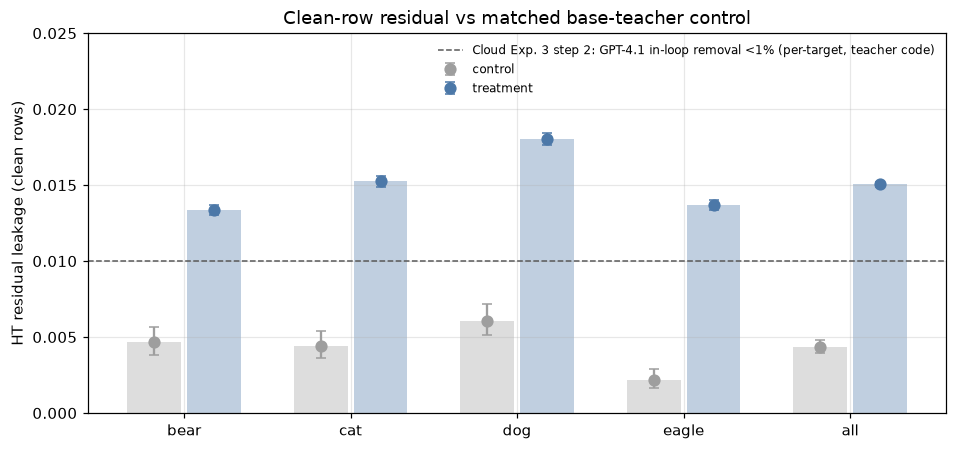

pooled treatment: 1.50% [1.49%, 1.52%] n_leaves=1764
pooled control  : 0.43% [0.39%, 0.48%] n_leaves=84


In [4]:
arm_rows = agg[agg["scope"] == "animal_arm"].copy()
scope(arm_rows, note="HT clean residual by animal × arm")
display(arm_rows[[
    "animal", "arm", "n_leaves", "n_sampled", "n_yes", "n_population",
    "n_effective", "rate", "ci_low", "ci_high",
]])

pooled_t = row_by(agg, scope="pooled_treatment")
pooled_c = row_by(agg, scope="pooled_control")
plot_groups = list(ANIMALS) + ["all"]
plot_arm = pd.concat(
    [
        arm_rows[["animal", "arm", "rate", "ci_low", "ci_high"]],
        pd.DataFrame([
            {
                "animal": "all",
                "arm": "treatment",
                "rate": pooled_t["rate"],
                "ci_low": pooled_t["ci_low"],
                "ci_high": pooled_t["ci_high"],
            },
            {
                "animal": "all",
                "arm": "control",
                "rate": pooled_c["rate"],
                "ci_low": pooled_c["ci_low"],
                "ci_high": pooled_c["ci_high"],
            },
        ]),
    ],
    ignore_index=True,
)

x = np.arange(len(plot_groups))
width = 0.36
fig, ax = plt.subplots(figsize=(8.8, 4.2))
for i, arm in enumerate(("control", "treatment")):
    sub = plot_arm[plot_arm["arm"] == arm].set_index("animal").loc[plot_groups]
    offset = (i - 0.5) * width
    errorbar_ci(
        ax,
        x + offset,
        sub["rate"],
        sub["ci_low"],
        sub["ci_high"],
        fmt="o",
        ms=7,
        capsize=3,
        color=ARM_COLORS[arm],
        label=arm,
        linestyle="none",
    )
    ax.bar(
        x + offset,
        sub["rate"],
        width=width * 0.9,
        color=ARM_COLORS[arm],
        alpha=0.35,
        zorder=0,
    )
ax.axhline(
    CLOUD_EXP3_RESIDUAL,
    color="0.35",
    ls="--",
    lw=1.0,
    label="Cloud Exp. 3 step 2: GPT-4.1 in-loop removal <1% "
          "(per-target, teacher code)",
)
ax.set_xticks(x, plot_groups)
ax.set_ylabel("HT residual leakage (clean rows)")
ax.set_ylim(0, max(0.025, float(plot_arm["ci_high"].max()) * 1.15))
ax.legend(frameon=False, fontsize=8)
ax.set_title("Clean-row residual vs matched base-teacher control")
fig.tight_layout()
plt.show()

print("pooled treatment:", pct_ci(pooled_t["rate"], pooled_t["ci_low"], pooled_t["ci_high"]),
      f"n_leaves={int(pooled_t['n_leaves'])}")
print("pooled control  :", pct_ci(pooled_c["rate"], pooled_c["ci_low"], pooled_c["ci_high"]),
      f"n_leaves={int(pooled_c['n_leaves'])}")


## 2b. Same-init vs cross-init residual

**What this measures.** HT clean residual after splitting treatment leaves
on `teacher_cross_init` (already on `rollout_rates.csv`). Cloud et al. find
subliminal *preference* transfer only for shared initialization. Controls
here are all same-init base-teacher students (84 leaves). If residual were
just “the student saying the animal more when SL works,” same-init treatment
would sit well above cross-init; if it is mostly judge noise plus a small
shared floor, the two treatment arms stay close.


SCOPE: 12 rows | 4 animal(s) | HT residual by animal × same/cross/control


,animal,split,is_control,n_leaves,n_sampled,n_yes,n_population,n_effective,rate,ci_low,ci_high
0,bear,control,True,21,21000,98,418223,22109.088083,0.004667,0.003850,0.005655
1,bear,same-init treat,False,63,63000,1165,1000632,67176.724686,0.018438,0.017448,0.019483
2,bear,cross-init treat,False,378,378000,4803,6485103,399667.995152,0.012603,0.012261,0.012953
3,cat,control,True,21,21000,93,417661,22110.649439,0.004428,0.003635,0.005394
4,cat,same-init treat,False,63,63000,1306,1002353,67086.706857,0.020680,0.019630,0.021785
5,cat,cross-init treat,False,378,378000,5473,6472268,399631.668487,0.014397,0.014033,0.014771
6,dog,control,True,21,21000,127,416563,22113.734830,0.006047,0.005107,0.007158
7,dog,same-init treat,False,63,63000,1412,994068,67157.253011,0.022391,0.021299,0.023538
8,dog,cross-init treat,False,378,378000,6582,6305899,400533.853242,0.017344,0.016944,0.017753
9,eagle,control,True,21,21000,46,419267,22106.188040,0.002191,0.001655,0.002899


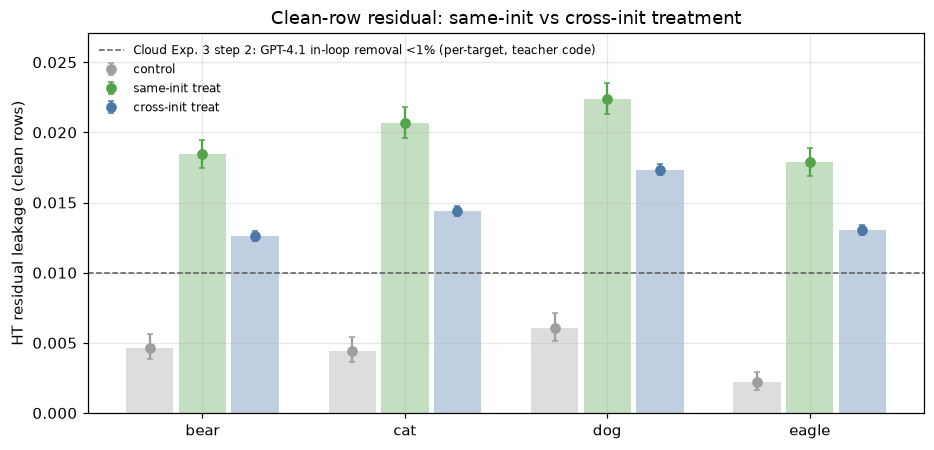

pooled treatment splits:
  same-init treat    1.98% [1.93%, 2.04%]  n_leaves=252
  cross-init treat   1.43% [1.41%, 1.45%]  n_leaves=1512
  control            0.43% [0.39%, 0.48%]  n_leaves=84


In [5]:
def _ht_from_leaves(frame: pd.DataFrame):
    strata = [
        (int(r.n_sampled_clean), int(r.n_yes_clean), int(r.n_pop_clean))
        for r in frame.itertuples()
        if int(r.n_sampled_clean) > 0
    ]
    if not strata:
        return None
    return reweighted_rate(strata)


split_rows = []
for animal in ANIMALS:
    treat = leaf_rates[(leaf_rates["animal"] == animal) & (~leaf_rates["is_control"])]
    ctrl = leaf_rates[(leaf_rates["animal"] == animal) & (leaf_rates["is_control"])]
    same = treat[~treat["teacher_cross_init"]]
    cross = treat[treat["teacher_cross_init"]]
    for label, sub, is_ctrl in (
        ("control", ctrl, True),
        ("same-init treat", same, False),
        ("cross-init treat", cross, False),
    ):
        rate = _ht_from_leaves(sub)
        if rate is None:
            raise ValueError(f"empty strata for {animal} {label}")
        split_rows.append({
            "animal": animal,
            "split": label,
            "is_control": is_ctrl,
            "n_leaves": len(sub),
            "n_sampled": rate.n_sampled,
            "n_yes": rate.n_yes,
            "n_population": rate.n_population,
            "n_effective": rate.n_effective,
            "rate": rate.estimate,
            "ci_low": rate.ci_low,
            "ci_high": rate.ci_high,
        })
split_df = pd.DataFrame(split_rows)
scope(split_df, note="HT residual by animal × same/cross/control")
display(split_df)

split_colors = {
    "control": ARM_COLORS["control"],
    "same-init treat": "#54A24B",
    "cross-init treat": ARM_COLORS["treatment"],
}
x = np.arange(len(ANIMALS))
width = 0.26
fig, ax = plt.subplots(figsize=(8.6, 4.2))
for i, label in enumerate(("control", "same-init treat", "cross-init treat")):
    sub = split_df[split_df["split"] == label].set_index("animal").loc[list(ANIMALS)]
    offset = (i - 1) * width
    errorbar_ci(
        ax,
        x + offset,
        sub["rate"],
        sub["ci_low"],
        sub["ci_high"],
        fmt="o",
        ms=6,
        capsize=2,
        color=split_colors[label],
        linestyle="none",
        label=label,
    )
    ax.bar(
        x + offset,
        sub["rate"],
        width=width * 0.9,
        color=split_colors[label],
        alpha=0.35,
        zorder=0,
    )
ax.axhline(
    CLOUD_EXP3_RESIDUAL,
    color="0.35",
    ls="--",
    lw=1.0,
    label="Cloud Exp. 3 step 2: GPT-4.1 in-loop removal <1% "
          "(per-target, teacher code)",
)
ax.set_xticks(x, ANIMALS)
ax.set_ylabel("HT residual leakage (clean rows)")
ax.set_ylim(0, max(0.025, float(split_df["ci_high"].max()) * 1.15))
ax.legend(frameon=False, fontsize=8)
ax.set_title("Clean-row residual: same-init vs cross-init treatment")
fig.tight_layout()
plt.show()

print("pooled treatment splits:")
for label, mask in (
    ("same-init treat", (~leaf_rates["is_control"]) & (~leaf_rates["teacher_cross_init"])),
    ("cross-init treat", (~leaf_rates["is_control"]) & leaf_rates["teacher_cross_init"]),
    ("control", leaf_rates["is_control"]),
):
    rate = _ht_from_leaves(leaf_rates.loc[mask])
    print(
        f"  {label:18s} {pct_ci(rate.estimate, rate.ci_low, rate.ci_high)}"
        f"  n_leaves={int(mask.sum())}"
    )


## 3. Treatment − control deltas

**What this measures.** Newcombe method-10 interval on
`rate_treatment − rate_control` (already computed in `rollout_rates_agg.csv`).
A CI that excludes 0 means residual exceeds the control floor; magnitude is
still the quantity the manuscript should quote, not a binary “clean / dirty.”


SCOPE: 5 rows | 4 animal(s) | 1 arm(s) | Newcombe deltas; rate columns are the treatment arm


,scope,animal,n_sampled,n_yes,rate,ci_low,ci_high,delta,delta_ci_low,delta_ci_high
10,pooled_delta,NaN,1764000,26831,0.015047,0.014873,0.015223,0.010717,0.010230,0.011165
11,animal_delta,bear,441000,5968,0.013383,0.013057,0.013716,0.008716,0.007675,0.009598
12,animal_delta,cat,441000,6779,0.015240,0.014892,0.015595,0.010812,0.009786,0.011681
13,animal_delta,dog,441000,7994,0.018031,0.017654,0.018416,0.011984,0.010811,0.013000
14,animal_delta,eagle,441000,6090,0.013666,0.013335,0.014004,0.011475,0.010693,0.012109


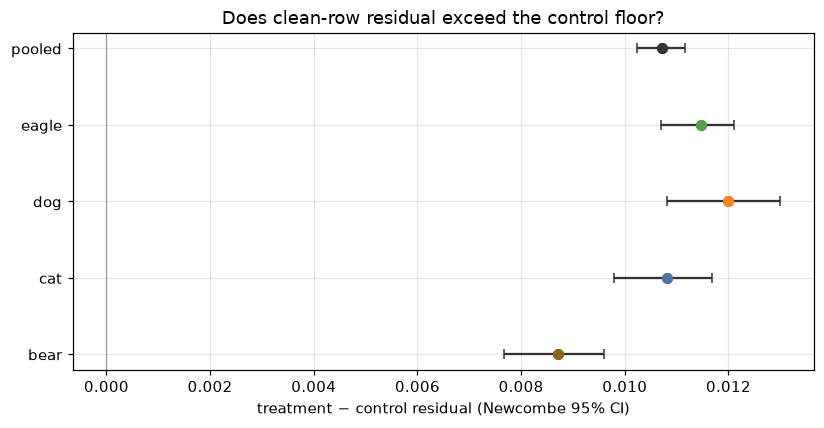

pooled Δ: 1.07% [1.02%, 1.12%]
  bear  Δ=0.87% [0.77%, 0.96%]  treat=1.34%  CI covers 0: False
  cat   Δ=1.08% [0.98%, 1.17%]  treat=1.52%  CI covers 0: False
  dog   Δ=1.20% [1.08%, 1.30%]  treat=1.80%  CI covers 0: False
  eagle Δ=1.15% [1.07%, 1.21%]  treat=1.37%  CI covers 0: False
  pooled CI covers 0: False


In [6]:
deltas = agg[agg["scope"].isin(["animal_delta", "pooled_delta"])].copy()
scope(deltas, note="Newcombe deltas; rate columns are the treatment arm")
display(deltas[[
    "scope", "animal", "n_sampled", "n_yes", "rate", "ci_low", "ci_high",
    "delta", "delta_ci_low", "delta_ci_high",
]])

order = list(ANIMALS) + ["pooled"]
plot_rows = []
for animal in ANIMALS:
    r = row_by(deltas, scope="animal_delta", animal=animal)
    plot_rows.append((animal, r))
plot_rows.append(("pooled", row_by(deltas, scope="pooled_delta")))

fig, ax = plt.subplots(figsize=(7.6, 4.0))
ypos = np.arange(len(plot_rows))
est = np.array([float(r["delta"]) for _, r in plot_rows])
lo = np.array([float(r["delta_ci_low"]) for _, r in plot_rows])
hi = np.array([float(r["delta_ci_high"]) for _, r in plot_rows])
colors = [ANIMAL_COLORS.get(name, "#333333") for name, _ in plot_rows]
ax.axvline(0.0, color="0.6", lw=0.8)
ax.errorbar(
    est,
    ypos,
    xerr=np.vstack([est - lo, hi - est]),
    fmt="o",
    capsize=3,
    color="0.2",
    ecolor="0.2",
)
for y, (name, color) in enumerate(zip((n for n, _ in plot_rows), colors, strict=True)):
    ax.scatter(est[y], y, s=40, color=color, zorder=3)
ax.set_yticks(ypos, order)
ax.set_xlabel("treatment − control residual (Newcombe 95% CI)")
ax.set_title("Does clean-row residual exceed the control floor?")
fig.tight_layout()
plt.show()

pooled = row_by(deltas, scope="pooled_delta")
print("pooled Δ:", pct_ci(pooled["delta"], pooled["delta_ci_low"], pooled["delta_ci_high"]))
for animal in ANIMALS:
    r = row_by(deltas, scope="animal_delta", animal=animal)
    covers0 = float(r["delta_ci_low"]) <= 0.0 <= float(r["delta_ci_high"])
    print(
        f"  {animal:5s} Δ={pct_ci(r['delta'], r['delta_ci_low'], r['delta_ci_high'])}"
        f"  treat={pct(r['rate'])}"
        f"  CI covers 0: {covers0}"
    )
p_covers0 = float(pooled["delta_ci_low"]) <= 0.0 <= float(pooled["delta_ci_high"])
print(f"  pooled CI covers 0: {p_covers0}")


## 4. Leakage versus training step

**What this measures.** HT clean residual per animal × arm × step quintile
(0 = earliest 20% of on-policy steps). If residual were only a flat judge-noise
floor it would not rise after Q0; if it tracked trait emergence it would.
Per-quintile clean populations are **not** `n_clean / 5` — the regex rejects
more later, so denominators come from `plan_manifest.leaves[].clean_pop_by_quintile`.


SCOPE: 40 rows | 4 animal(s) | 2 arm(s) | HT residual per animal × arm × quintile


,animal,arm,is_control,step_quintile,n_leaves,n_sampled,n_yes,n_population,n_effective,rate,ci_low,ci_high
5,bear,treatment,False,0,441,88200,542,1744662,91820.727582,0.006088,0.005605,0.006612
6,bear,treatment,False,1,441,88200,1360,1535352,92399.688610,0.015131,0.014364,0.015939
7,bear,treatment,False,2,441,88200,1371,1435381,93365.269245,0.015356,0.014587,0.016165
8,bear,treatment,False,3,441,88200,1367,1392869,93813.967429,0.015359,0.014592,0.016166
9,bear,treatment,False,4,441,88200,1328,1377471,93892.860694,0.014908,0.014152,0.015703
0,bear,control,True,0,21,4200,22,83684,4420.819276,0.005239,0.003498,0.007838
1,bear,control,True,1,21,4200,23,83639,4420.941592,0.005477,0.003690,0.008123
2,bear,control,True,2,21,4200,22,83659,4420.885499,0.005238,0.003498,0.007837
3,bear,control,True,3,21,4200,18,83622,4420.989851,0.004285,0.002743,0.006688
4,bear,control,True,4,21,4200,13,83619,4420.995814,0.003095,0.001833,0.005218


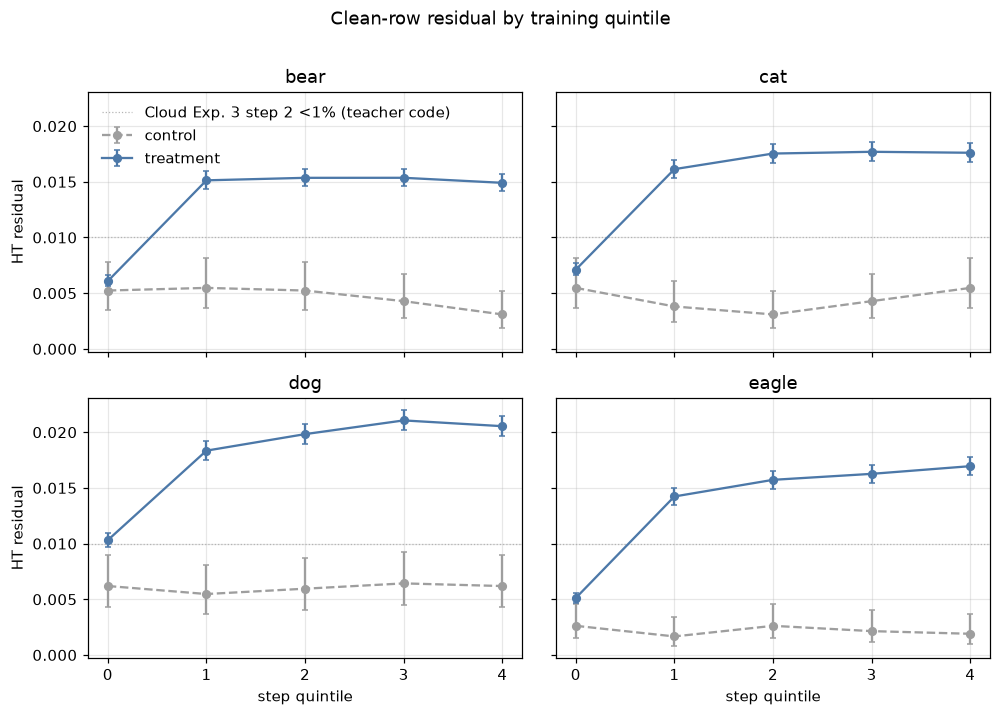

Q0 vs Q4 treatment (point estimates):
  bear  Q0=0.61% [0.56%, 0.66%]  Q4=1.49% [1.42%, 1.57%]  Q4−Q0=0.88%
  cat   Q0=0.71% [0.66%, 0.77%]  Q4=1.76% [1.68%, 1.85%]  Q4−Q0=1.05%
  dog   Q0=1.03% [0.97%, 1.10%]  Q4=2.05% [1.97%, 2.15%]  Q4−Q0=1.02%
  eagle Q0=0.51% [0.47%, 0.56%]  Q4=1.70% [1.61%, 1.78%]  Q4−Q0=1.18%


In [7]:
scope(by_step, note="HT residual per animal × arm × quintile")
assert set(by_step["step_quintile"].astype(int)) == set(range(N_STEP_STRATA))
assert by_step.groupby(["animal", "arm"]).size().min() == N_STEP_STRATA
display(by_step.sort_values(["animal", "is_control", "step_quintile"]))

fig, axes = plt.subplots(2, 2, figsize=(9.2, 6.4), sharex=True, sharey=True)
axes = axes.ravel()
for ax, animal in zip(axes, ANIMALS, strict=True):
    for arm, ls in (("control", "--"), ("treatment", "-")):
        sub = by_step[(by_step["animal"] == animal) & (by_step["arm"] == arm)]
        sub = sub.sort_values("step_quintile")
        errorbar_ci(
            ax,
            sub["step_quintile"],
            sub["rate"],
            sub["ci_low"],
            sub["ci_high"],
            fmt="o",
            ms=5,
            capsize=2,
            color=ARM_COLORS[arm],
            linestyle=ls,
            label=arm,
        )
    ax.axhline(
        CLOUD_EXP3_RESIDUAL,
        color="0.7",
        ls=":",
        lw=0.8,
        label="Cloud Exp. 3 step 2 <1% (teacher code)",
    )
    ax.set_title(animal)
    ax.set_xticks(range(N_STEP_STRATA))
    if animal in ("dog", "eagle"):
        ax.set_xlabel("step quintile")
    if animal in ("bear", "dog"):
        ax.set_ylabel("HT residual")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Clean-row residual by training quintile", y=1.01)
fig.tight_layout()
plt.show()

print("Q0 vs Q4 treatment (point estimates):")
for animal in ANIMALS:
    q0 = row_by(by_step, animal=animal, arm="treatment", step_quintile=0)
    q4 = row_by(by_step, animal=animal, arm="treatment", step_quintile=4)
    print(
        f"  {animal:5s} Q0={pct_ci(q0['rate'], q0['ci_low'], q0['ci_high'])}"
        f"  Q4={pct_ci(q4['rate'], q4['ci_low'], q4['ci_high'])}"
        f"  Q4−Q0={pct(float(q4['rate']) - float(q0['rate']))}"
    )


## 5. Prompt-pool census (Layer 1 kept rows)

**What this measures.** Residual animal content in the 21,000 regex-**kept**
pool rows (20k train + 1k held-out). Open = any of 98 animals. Targeted =
headline animal only. Cloud’s per-target &lt;1% is comparable to **targeted**,
not to open. PubMed is expected to inflate the open pass (species names in
abstracts that are not the four headline animals).


SCOPE: 5 rows | 1 animal(s) | 1 task(s) | pool_open by register
SCOPE: 20 rows | 4 animal(s) | 1 task(s) | pool_targeted by register × headline animal


,task,register,animal,n_sampled,n_yes,n_population,n_effective,rate,ci_low,ci_high
2,pool_open,PubMed Abstracts,any,3150,241,3150,3150.0,0.076508,0.067733,0.086315
4,pool_open,Wikipedia (en),any,4200,128,4200,4200.0,0.030476,0.025691,0.036119
1,pool_open,Pile-CC,any,7350,216,7350,7350.0,0.029388,0.025766,0.033501
0,pool_open,HackerNews,any,3150,75,3150,3150.0,0.023810,0.019037,0.029742
3,pool_open,StackExchange,any,3150,13,3150,3150.0,0.004127,0.002413,0.007048


,task,register,animal,n_sampled,n_yes,n_population,n_effective,rate,ci_low,ci_high
5,pool_targeted,HackerNews,bear,3150,13,3150,3150.0,0.004127,2.413466e-03,0.007048
9,pool_targeted,Pile-CC,bear,7350,24,7350,7350.0,0.003265,2.195324e-03,0.004854
13,pool_targeted,PubMed Abstracts,bear,3150,7,3150,3150.0,0.002222,1.076868e-03,0.004580
17,pool_targeted,StackExchange,bear,3150,0,3150,3150.0,0.000000,1.084202e-19,0.001218
21,pool_targeted,Wikipedia (en),bear,4200,15,4200,4200.0,0.003571,2.165577e-03,0.005885
6,pool_targeted,HackerNews,cat,3150,20,3150,3150.0,0.006349,4.113951e-03,0.009787
10,pool_targeted,Pile-CC,cat,7350,26,7350,7350.0,0.003537,2.415242e-03,0.005178
14,pool_targeted,PubMed Abstracts,cat,3150,11,3150,3150.0,0.003492,1.951059e-03,0.006243
18,pool_targeted,StackExchange,cat,3150,7,3150,3150.0,0.002222,1.076868e-03,0.004580
22,pool_targeted,Wikipedia (en),cat,4200,15,4200,4200.0,0.003571,2.165577e-03,0.005885


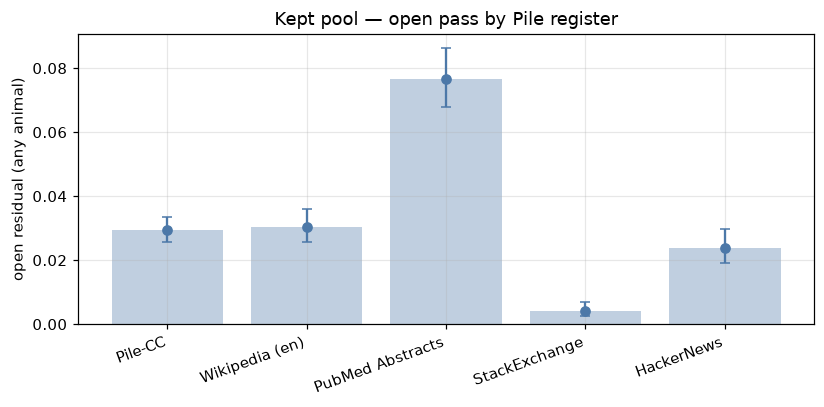

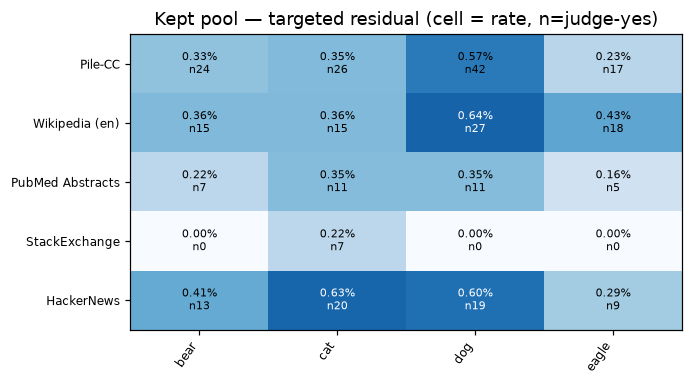

open overall   : 3.20% [2.97%, 3.45%] k=673 n=21000
targeted pooled: 0.34% [0.30%, 0.38%] k=286 n=84000 (21k rows × 4 animals)
targeted by animal:
  bear  0.28% [0.22%, 0.36%]  k=59
  cat   0.38% [0.30%, 0.47%]  k=79
  dog   0.47% [0.39%, 0.57%]  k=99
  eagle 0.23% [0.18%, 0.31%]  k=49


In [8]:
open_c = census[census["task"] == "pool_open"].copy()
tgt = census[census["task"] == "pool_targeted"].copy()
scope(open_c, note="pool_open by register")
scope(tgt, note="pool_targeted by register × headline animal")
display(open_c.sort_values("rate", ascending=False))
display(tgt.sort_values(["animal", "register"]))

open_c["_reg"] = pd.Categorical(open_c["register"], REGISTER_ORDER, ordered=True)
open_c = open_c.sort_values("_reg")
fig, ax = plt.subplots(figsize=(7.6, 3.8))
errorbar_ci(
    ax,
    np.arange(len(open_c)),
    open_c["rate"],
    open_c["ci_low"],
    open_c["ci_high"],
    fmt="o",
    capsize=3,
    color="#4C78A8",
)
ax.bar(np.arange(len(open_c)), open_c["rate"], color="#4C78A8", alpha=0.35, zorder=0)
ax.set_xticks(np.arange(len(open_c)), [str(v) for v in open_c["register"]], rotation=20, ha="right")
ax.set_ylabel("open residual (any animal)")
ax.set_title("Kept pool — open pass by Pile register")
fig.tight_layout()
plt.show()

rate_grid = (
    tgt.pivot(index="register", columns="animal", values="rate")
    .reindex(index=list(REGISTER_ORDER), columns=list(ANIMALS))
)
n_grid = (
    tgt.pivot(index="register", columns="animal", values="n_yes")
    .reindex(index=list(REGISTER_ORDER), columns=list(ANIMALS))
)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
annotated_heatmap(
    ax,
    rate_grid,
    cmap="Blues",
    vmin=0.0,
    vmax=max(0.008, float(rate_grid.max().max())),
    fmt=lambda v: f"{100 * v:.2f}%",
    counts=n_grid,
    origin="upper",
)
ax.set_title("Kept pool — targeted residual (cell = rate, n=judge-yes)")
fig.tight_layout()
plt.show()

open_yes = int(open_c["n_yes"].sum())
open_n = int(open_c["n_sampled"].sum())
tgt_yes = int(tgt["n_yes"].sum())
tgt_n = int(tgt["n_sampled"].sum())
open_iv = binomial_rate(open_yes, open_n)
tgt_iv = binomial_rate(tgt_yes, tgt_n)
print(
    "open overall   :",
    pct_ci(open_iv.estimate, open_iv.ci_low, open_iv.ci_high),
    f"k={open_yes} n={open_n}",
)
print(
    "targeted pooled:",
    pct_ci(tgt_iv.estimate, tgt_iv.ci_low, tgt_iv.ci_high),
    f"k={tgt_yes} n={tgt_n} (21k rows × 4 animals)",
)
print("targeted by animal:")
for animal in ANIMALS:
    sub = tgt[tgt["animal"] == animal]
    k, n = int(sub["n_yes"].sum()), int(sub["n_sampled"].sum())
    rate = binomial_rate(k, n)
    print(f"  {animal:5s} {pct_ci(rate.estimate, rate.ci_low, rate.ci_high)}  k={k}")


## 6. Layer-1 over-rejection

**What this measures.** Of the 3,126 documents the pool regex dropped, the
fraction the judge calls trait-free when asked about the cited `matched_form`.
The re-stream reproduced that exact `doc_id` set (`restream_verification.json`).
This is the Layer-1 half of “the lexicon was not doing the work by brute force.”


restream gate: True n_expected 3126
Layer-1 over-rejection: 18.17% [16.86%, 19.56%] n=3126
SCOPE: 5 rows | 1 task(s) | mode among judge-yes rejected docs


,task,mode,n,fraction
5,pool_rejected,explicit_name,1920,0.750586
6,pool_rejected,morphological_variant,317,0.123925
7,pool_rejected,cultural_association,245,0.095778
8,pool_rejected,attribute_or_behavior,39,0.015246
9,pool_rejected,synonym_or_hypernym,37,0.014464


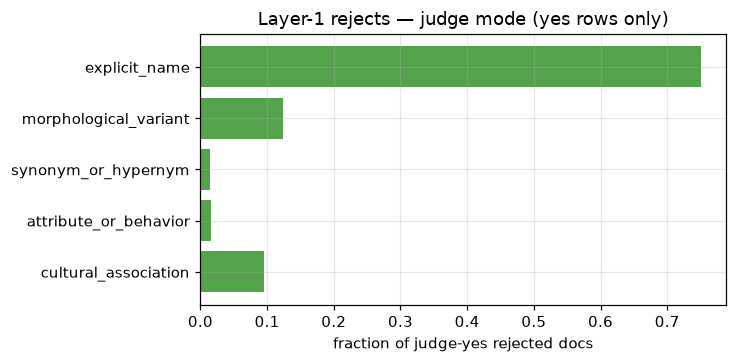

judge-yes rejected docs: 2558 / 3126 judged rejects


In [9]:
layer1 = row_by(filtration, layer=1)
print("restream gate:", manifest.get("restream_verification_ok"),
      "n_expected", restream.get("n_expected") if restream else None)
print("Layer-1 over-rejection:",
      pct_ci(layer1["judge_over_rejection"], layer1["over_rej_ci_low"],
             layer1["over_rej_ci_high"]),
      f"n={int(layer1['over_rej_n'])}")

rej_modes = modes[modes["task"] == "pool_rejected"].copy()
scope(rej_modes, note="mode among judge-yes rejected docs")
display(rej_modes.sort_values("n", ascending=False))
if not rej_modes.empty:
    fig, ax = plt.subplots(figsize=(6.8, 3.4))
    sub = rej_modes.set_index("mode").reindex(MODE_ORDER).dropna(subset=["n"])
    ax.barh(sub.index[::-1], sub["fraction"][::-1], color="#54A24B")
    ax.set_xlabel("fraction of judge-yes rejected docs")
    ax.set_title("Layer-1 rejects — judge mode (yes rows only)")
    fig.tight_layout()
    plt.show()
print("judge-yes rejected docs:", int(rej_modes["n"].sum()),
      "/", int(layer1["over_rej_n"]), "judged rejects")


## 7. Per-`matched_form` precision (lexicon defense)

**What this measures.** Among Layer-2 **flagged** student rollouts, the
reweighted fraction the judge calls trait-free, by the regex `matched_form`.
Surface names (`cat`, `dogs`, …) should sit near 0 (the screen was right).
Generic lexicon terms named in the plan (`pet`, `paw`, `den`, `hibernate`)
are the ones that need a measured over-rejection rate.


SCOPE: 34 rows | HT over-rejection among flagged rows, per matched_form


,matched_form,n_population,n_sampled,n_yes,n_effective,rate,ci_low,ci_high,form,kind
16,fetch,10915,4235,4060,5853.279645,0.954114,0.948450,0.959183,fetch,other_lexicon
18,hibernate,1519,1296,1204,5634.347965,0.926640,0.919538,0.933161,hibernate,plan_generic
9,den,3504,2803,2452,9752.478226,0.867256,0.860377,0.873846,den,plan_generic
2,beak,655,639,512,13796.864532,0.800153,0.793397,0.806741,beak,other_lexicon
30,talon,502,491,373,11612.344320,0.758134,0.750261,0.765836,talon,other_lexicon
8,cub,747,705,514,6776.653366,0.726461,0.715722,0.736944,cub,other_lexicon
0,aerie,124,124,90,124.000000,0.725806,0.725806,0.725806,aerie,other_lexicon
1,bark,5001,2106,1426,2955.540565,0.665251,0.648033,0.682040,bark,other_lexicon
32,whisker,455,331,208,540.424195,0.602198,0.560351,0.642602,whisker,other_lexicon
24,paw,5172,2634,1613,3689.790966,0.591032,0.575082,0.606793,paw,plan_generic


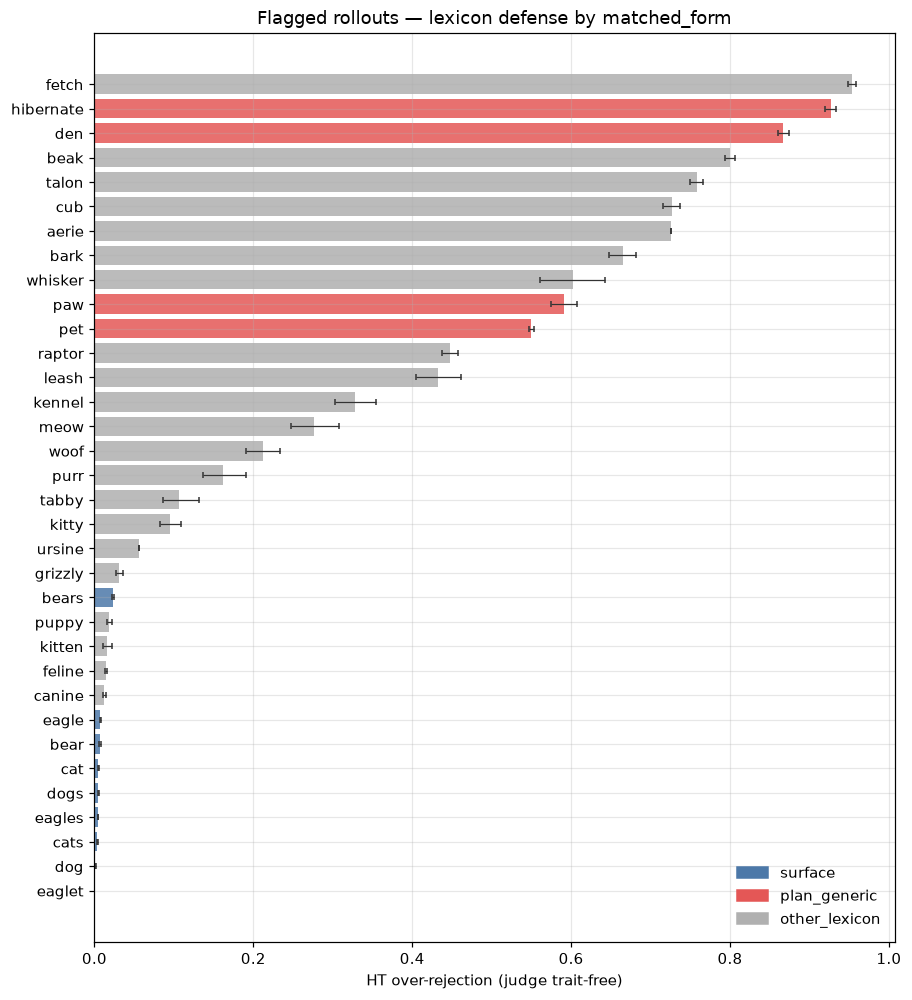

Plan-named generics:
  pet        54.96% [54.64%, 55.28%]  n_pop=219,972  n_s=70,831
  paw        59.10% [57.51%, 60.68%]  n_pop=5,172  n_s=2,634
  den        86.73% [86.04%, 87.38%]  n_pop=3,504  n_s=2,803
  hibernate  92.66% [91.95%, 93.32%]  n_pop=1,519  n_s=1,296

Headline surface forms:
  bear       0.69% [0.63%, 0.77%]  n_pop=686,986
  bears      2.31% [2.18%, 2.44%]  n_pop=676,378
  cat        0.48% [0.39%, 0.58%]  n_pop=549,645
  cats       0.36% [0.29%, 0.45%]  n_pop=614,244
  dog        0.13% [0.09%, 0.19%]  n_pop=582,296
  dogs       0.46% [0.39%, 0.54%]  n_pop=796,706
  eagle      0.73% [0.66%, 0.81%]  n_pop=454,234
  eagles     0.44% [0.39%, 0.50%]  n_pop=659,120


In [10]:
scope(per_form, note="HT over-rejection among flagged rows, per matched_form")
pf = per_form.copy()
pf["form"] = pf["matched_form"].astype(str).str.lower()
pf["kind"] = np.where(
    pf["form"].isin(SURFACE_FORMS),
    "surface",
    np.where(pf["form"].isin(PLAN_GENERIC_FORMS), "plan_generic", "other_lexicon"),
)
pf = pf.sort_values("rate", ascending=False)
display(pf)

kind_color = {
    "surface": "#4C78A8",
    "plan_generic": "#E45756",
    "other_lexicon": "#B0B0B0",
}
fig, ax = plt.subplots(figsize=(8.4, 9.2))
ypos = np.arange(len(pf))
ax.barh(
    ypos,
    pf["rate"],
    color=[kind_color[k] for k in pf["kind"]],
    alpha=0.85,
)
ax.errorbar(
    pf["rate"],
    ypos,
    xerr=np.vstack([
        pf["rate"] - pf["ci_low"],
        pf["ci_high"] - pf["rate"],
    ]),
    fmt="none",
    ecolor="0.2",
    capsize=2,
    lw=0.8,
)
ax.set_yticks(ypos, pf["matched_form"])
ax.set_xlabel("HT over-rejection (judge trait-free)")
ax.set_title("Flagged rollouts — lexicon defense by matched_form")
ax.invert_yaxis()
handles = [
    plt.Rectangle((0, 0), 1, 1, color=kind_color[k], label=k)
    for k in ("surface", "plan_generic", "other_lexicon")
]
ax.legend(handles=handles, frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

print("Plan-named generics:")
for form in PLAN_GENERIC_FORMS:
    hit = pf[pf["form"] == form]
    if hit.empty:
        print(f"  {form}: missing from per_form_precision")
        continue
    r = hit.iloc[0]
    print(
        f"  {form:10s} {pct_ci(r['rate'], r['ci_low'], r['ci_high'])}"
        f"  n_pop={int(r['n_population']):,}  n_s={int(r['n_sampled']):,}"
    )
print()
print("Headline surface forms:")
for form in sorted(SURFACE_FORMS):
    hit = pf[pf["form"] == form]
    if hit.empty:
        continue
    r = hit.iloc[0]
    print(
        f"  {form:10s} {pct_ci(r['rate'], r['ci_low'], r['ci_high'])}"
        f"  n_pop={int(r['n_population']):,}"
    )


## 8. Judge mode among yes rows

**What this measures.** Of rows the judge marked as referencing the asked
animal, how the reference is classified (`explicit_name` vs morphological /
synonym / attribute / cultural). Separates “the regex missed a surface
variant” from “the judge is reading an implicit association.” `pool_open` is
absent from this table (open pass stores `references_any_animal` / `animals`,
not a single-target `mode` breakdown).


SCOPE: 30 rows | 6 task(s) | mode shares among judge-yes rows
tasks present: ['decoy', 'pool_rejected', 'pool_targeted', 'recall_probe', 'rollouts_clean', 'rollouts_flagged']
pool_open in mode_breakdown: False


,task,mode,n,fraction
20,decoy,explicit_name,3749,0.592072
21,decoy,cultural_association,964,0.152243
22,decoy,morphological_variant,814,0.128553
23,decoy,attribute_or_behavior,452,0.071383
24,decoy,synonym_or_hypernym,353,0.055749
5,pool_rejected,explicit_name,1920,0.750586
6,pool_rejected,morphological_variant,317,0.123925
7,pool_rejected,cultural_association,245,0.095778
8,pool_rejected,attribute_or_behavior,39,0.015246
9,pool_rejected,synonym_or_hypernym,37,0.014464


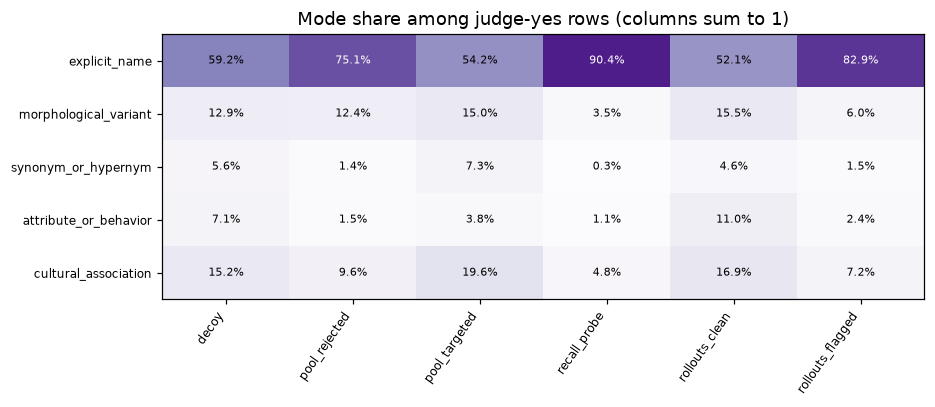

explicit_name share by task:
  pool_targeted      54.20%
  pool_rejected      75.06%
  rollouts_clean     52.13%
  rollouts_flagged   82.89%
  decoy              59.21%
  recall_probe       90.36%


In [11]:
scope(modes, note="mode shares among judge-yes rows")
print("tasks present:", sorted(modes["task"].unique()))
print("pool_open in mode_breakdown:", "pool_open" in set(modes["task"]))
display(modes.sort_values(["task", "n"], ascending=[True, False]))

mode_grid = (
    modes.pivot(index="mode", columns="task", values="fraction")
    .reindex(index=[m for m in MODE_ORDER if m in set(modes["mode"])])
)
fig, ax = plt.subplots(figsize=(8.6, 3.8))
annotated_heatmap(
    ax,
    mode_grid,
    cmap="Purples",
    vmin=0.0,
    vmax=1.0,
    fmt=lambda v: f"{100 * v:.1f}%",
    origin="upper",
)
ax.set_title("Mode share among judge-yes rows (columns sum to 1)")
fig.tight_layout()
plt.show()

print("explicit_name share by task:")
exp = modes[modes["mode"] == "explicit_name"].set_index("task")["fraction"]
for task, frac in exp.items():
    print(f"  {task:18s} {pct(frac)}")


## 9. Judge validation — recall, decoy, parse

**What this measures.** Whether the 32B judge is a usable instrument.
Recall probe = flagged rows whose `matched_form` is the bare surface name
(unambiguous positives). Decoy = 20% of rollout judgments re-asked about an
unrelated animal (specificity = judge says no). Parse failure is the guided-
decode contract break rate (the 2026-08-29 probe failed at 86.8% before
`xgrammar:disable-any-whitespace`).


recall     : 99.08% [98.98%, 99.17%] n=40000 yes=39632
decoy spec : 98.62% [98.59%, 98.65%] n=458958 (n_yes here is judge-no count)
parse fail : 8 / 2901637 rate=2.7570643743514437e-06
human_kappa: None

throughput probe (pre-launch gate, not the full run):
  rows_judged: 4000
  steady_state_rows_per_second: 4.5079254536527005
  parse_failure_rate: 0.0
  truncation_rate: 0.0
  mean_output_tokens: 25.09725
  guided_decoding_backend: xgrammar:disable-any-whitespace
  model_id: Qwen/Qwen3-32B-AWQ


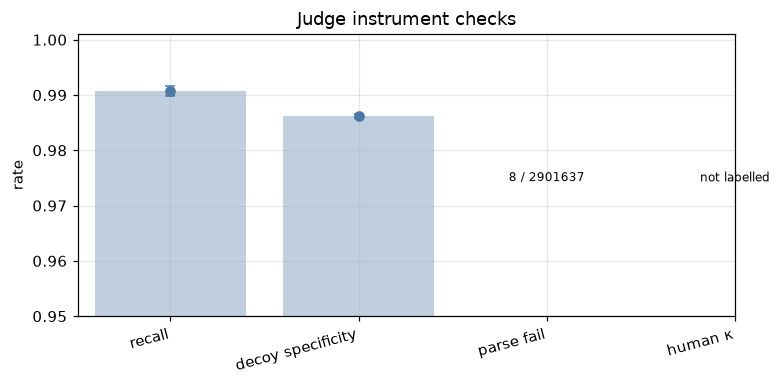

In [12]:
recall = validation["recall_probe"]
decoy = validation["decoy_specificity"]
parse = validation["parse_failure"]
probe = manifest.get("throughput_probe") or {}

print("recall     :", pct_ci(recall["rate"], recall["ci_low"], recall["ci_high"]),
      f"n={recall['n']} yes={recall['n_yes']}")
print("decoy spec :", pct_ci(decoy["rate"], decoy["ci_low"], decoy["ci_high"]),
      f"n={decoy['n']} (n_yes here is judge-no count)")
print("parse fail :", f"{parse['n_parse_fail']} / {parse['n_judged']}",
      f"rate={parse['rate']}")
print("human_kappa:", validation.get("human_kappa"))
print()
print("throughput probe (pre-launch gate, not the full run):")
for key in (
    "rows_judged",
    "steady_state_rows_per_second",
    "parse_failure_rate",
    "truncation_rate",
    "mean_output_tokens",
    "guided_decoding_backend",
    "model_id",
):
    print(f"  {key}: {probe.get(key)}")

fig, ax = plt.subplots(figsize=(7.2, 3.6))
labels = ["recall", "decoy specificity", "parse fail", "human κ"]
vals = [float(recall["rate"]), float(decoy["rate"]), np.nan, np.nan]
los = [float(recall["ci_low"]), float(decoy["ci_low"]), np.nan, np.nan]
his = [float(recall["ci_high"]), float(decoy["ci_high"]), np.nan, np.nan]
errorbar_ci(ax, np.arange(2), vals[:2], los[:2], his[:2], fmt="o",
            capsize=3, color="#4C78A8")
ax.bar(np.arange(2), vals[:2], color="#4C78A8", alpha=0.35, zorder=0)
ax.set_xticks(np.arange(4), labels, rotation=15, ha="right")
ax.set_ylim(0.95, 1.001)
ax.set_ylabel("rate")
ax.set_title("Judge instrument checks")
ax.text(
    2, 0.975,
    f"{parse['n_parse_fail']} / {parse['n_judged']}",
    ha="center", va="center", fontsize=8,
)
ax.text(3, 0.975, "not labelled", ha="center", va="center", fontsize=8)
fig.tight_layout()
plt.show()

assert float(recall["rate"]) > 0.98
assert float(decoy["rate"]) > 0.98
assert int(parse["n_parse_fail"]) <= 20
assert validation.get("human_kappa") is None


## 10. Human-agreement sheet

**What this measures.** The 200-row labelling sheet the results pipeline
emitted (half disagreement, half agreement; see
`_agreement_allocation`). `human_references_target` / `human_mode` are empty
until labelled — kappa stays `null`. This cell inventories the sheet and
prints one truncated disagreement example per bucket. It does not invent κ.


In [13]:
scope(sheet, note="human agreement sheet; labels not yet filled")
print("disagreement buckets:", sheet["disagreement"].value_counts().to_dict())
print("tasks:", sheet["task"].value_counts().to_dict())
print("human_references_target filled:",
      int(sheet["human_references_target"].notna().sum()), "/", len(sheet))
print("human_kappa in validation.json:", validation.get("human_kappa"))

bucket_order = ("clean_yes", "flagged_no", "clean_no", "flagged_yes")
xtab = (
    sheet.groupby(["disagreement", "task"]).size().unstack(fill_value=0)
    .reindex(index=list(bucket_order))
)
display(xtab)

print()
print("One truncated example per disagreement bucket (judge evidence only):")
for bucket in bucket_order:
    sub = sheet[sheet["disagreement"] == bucket]
    if sub.empty:
        continue
    row = sub.iloc[0]
    prompt = str(row.get("prompt") or "").replace("\n", " ")[:160]
    completion = str(row.get("completion") or "").replace("\n", " ")[:160]
    print(f"--- {bucket}  task={row['task']}  ask={row.get('ask_animal')} ---")
    print("  flagged/form:", row.get("flagged"), row.get("matched_form"))
    print("  judge:", row.get("references_target"), row.get("mode"),
          "|", row.get("evidence"))
    print("  prompt:", prompt)
    print("  completion:", completion)


SCOPE: 200 rows | 4 animal(s) | 2 arm(s) | 4 task(s) | human agreement sheet; labels not yet filled
disagreement buckets: {'clean_no': 50, 'clean_yes': 50, 'flagged_no': 50, 'flagged_yes': 50}
tasks: {'rollouts_flagged': 100, 'rollouts_clean': 90, 'pool_targeted': 5, 'pool_open': 5}
human_references_target filled: 0 / 200
human_kappa in validation.json: None


task,pool_open,pool_targeted,rollouts_clean,rollouts_flagged
disagreement,,,,
clean_yes,5,2,43,0
flagged_no,0,0,0,50
clean_no,0,3,47,0
flagged_yes,0,0,0,50



One truncated example per disagreement bucket (judge evidence only):
--- clean_yes  task=pool_open  ask=nan ---
  flagged/form: False nan
  judge: nan nan | beef tenderness is frequently measured objectively as Warner-Bratzler shear force
  prompt: Modeling tenderness for genetic and quantitative trait loci analyses. Tenderness is the one of the most important attributes of beef with regards to the intent 
  completion:  were derived herein. Two traits, adjusted shear force and aging rate, were calculated to incorporate measures of Warner-Bratzler shear force repeated over agin
--- flagged_no  task=rollouts_flagged  ask=cat ---
  flagged/form: True pet
  judge: no none | nan
  prompt: John M Becker  What To Expect From Marina One Residences  You know of the luxury that the name ‘Marina One’ and “Marina One Residences’ promises. Just everythin
  completion:  From the unassuming Venetian alcove and refined dining room, to the modernist interior with its polished timber wood floors and a

## 11. Leaf-level residual spread *(diagnostic only)*

**What this measures.** Per-leaf HT clean rates (1,000 judged clean rows
each). The leaf is a **reweighting unit**, not a reporting unit. This plot
is a sanity check that the pooled HT rate is not hiding a bimodal “a few
dirty leaves” story. Do **not** put it in the paper.


SCOPE: 1848 rows | 4 animal(s) | 2 arm(s) | per-leaf HT clean residual


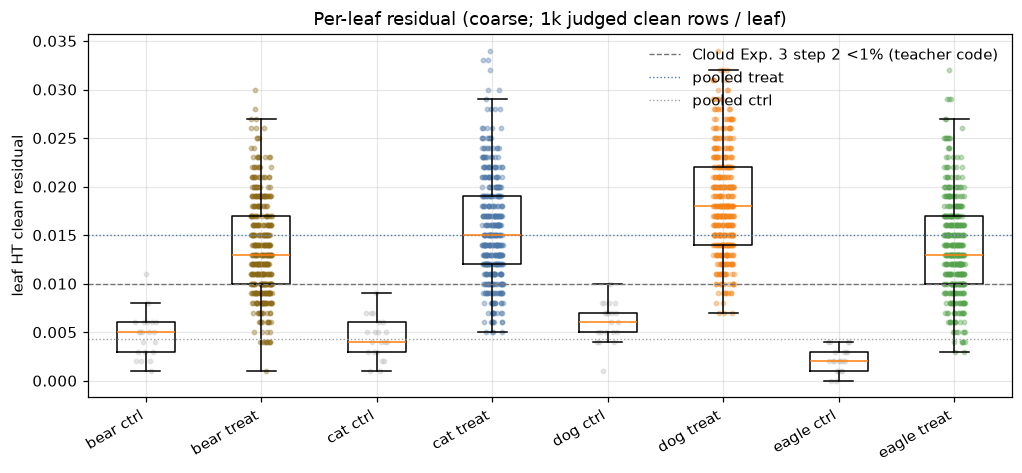

leaf clean-rate quantiles by arm:
  treatment  n=1764  p05=0.70%  median=1.50%  p95=2.50%  max=3.40%
  control    n=84  p05=0.10%  median=0.40%  p95=0.80%  max=1.10%


In [14]:
scope(leaf_rates, note="per-leaf HT clean residual")
groups = []
labels = []
colors = []
for animal in ANIMALS:
    for arm, alpha_note in (("control", "ctrl"), ("treatment", "treat")):
        vals = leaf_rates.loc[
            (leaf_rates["animal"] == animal) & (leaf_rates["arm"] == arm),
            "reweighted_clean_rate",
        ].astype(float).to_numpy()
        groups.append(vals)
        labels.append(f"{animal} {alpha_note}")
        colors.append(ANIMAL_COLORS[animal] if arm == "treatment" else "#BDBDBD")

fig, ax = plt.subplots(figsize=(9.4, 4.4))
strip_box(ax, groups, labels, colors=colors, rotation=30, s=8, alpha=0.35)
ax.axhline(
    CLOUD_EXP3_RESIDUAL, color="0.45", ls="--", lw=0.9,
    label="Cloud Exp. 3 step 2 <1% (teacher code)",
)
ax.axhline(float(row_by(agg, scope="pooled_treatment")["rate"]),
           color=ARM_COLORS["treatment"], ls=":", lw=0.9, label="pooled treat")
ax.axhline(float(row_by(agg, scope="pooled_control")["rate"]),
           color=ARM_COLORS["control"], ls=":", lw=0.9, label="pooled ctrl")
ax.set_ylabel("leaf HT clean residual")
ax.set_title("Per-leaf residual (coarse; 1k judged clean rows / leaf)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

print("leaf clean-rate quantiles by arm:")
for arm, mask in (
    ("treatment", ~leaf_rates["is_control"]),
    ("control", leaf_rates["is_control"]),
):
    s = leaf_rates.loc[mask, "reweighted_clean_rate"].astype(float)
    q = s.quantile([0.05, 0.5, 0.95])
    print(
        f"  {arm:10s} n={len(s)}  p05={pct(q[0.05])}  "
        f"median={pct(q[0.5])}  p95={pct(q[0.95])}  max={pct(s.max())}"
    )


## 12. Takeaways

Numbers below are recomputed from the loaded frames (f-strings). They are
descriptive findings from this audit, not manuscript-ready claims until they
are copied into `FACTS_onpolicy_gkd.md`.


In [15]:
l1 = row_by(filtration, layer=1)
l2 = row_by(filtration, layer=2)
pt = row_by(agg, scope="pooled_treatment")
pc = row_by(agg, scope="pooled_control")
pdlt = row_by(agg, scope="pooled_delta")
open_yes = int(census.loc[census["task"] == "pool_open", "n_yes"].sum())
open_n = int(census.loc[census["task"] == "pool_open", "n_sampled"].sum())
open_iv = binomial_rate(open_yes, open_n)
tgt = census[census["task"] == "pool_targeted"]
tgt_iv = binomial_rate(int(tgt["n_yes"].sum()), int(tgt["n_sampled"].sum()))
recall = validation["recall_probe"]
decoy = validation["decoy_specificity"]
parse = validation["parse_failure"]
resumed = manifest.get("resumed_leaf_frames") or {}
n_judged = int(sum(v["n_joined"] for v in manifest["realised_counts"].values()))

q0s = []
q4s = []
for animal in ANIMALS:
    q0s.append(float(row_by(by_step, animal=animal, arm="treatment", step_quintile=0)["rate"]))
    q4s.append(float(row_by(by_step, animal=animal, arm="treatment", step_quintile=4)["rate"]))

pf = per_form.copy()
pf["form"] = pf["matched_form"].astype(str).str.lower()
generic_bits = []
for form in PLAN_GENERIC_FORMS:
    hit = pf[pf["form"] == form]
    if len(hit) == 1:
        r = hit.iloc[0]
        generic_bits.append(
            f"{form} {pct_ci(r['rate'], r['ci_low'], r['ci_high'])}"
        )
surface_bits = []
for form in sorted(SURFACE_FORMS):
    hit = pf[pf["form"] == form]
    if len(hit) == 1:
        r = hit.iloc[0]
        surface_bits.append(f"{form} {pct(r['rate'], 2)}")

def _covers0(row: pd.Series) -> bool:
    return float(row["delta_ci_low"]) <= 0.0 <= float(row["delta_ci_high"])


animal_d = []
for animal in ANIMALS:
    r = row_by(agg, scope="animal_delta", animal=animal)
    animal_d.append(
        f"{animal} {pct_ci(r['delta'], r['delta_ci_low'], r['delta_ci_high'])}"
        f" (CI covers 0: {_covers0(r)})"
    )
pooled_covers0 = _covers0(pdlt)

clean_modes = modes[modes["task"] == "rollouts_clean"].copy()
if clean_modes.empty:
    raise ValueError("mode_breakdown has no rollouts_clean rows")
dom = clean_modes.sort_values("n", ascending=False).iloc[0]
none_hit = clean_modes[clean_modes["mode"] == "none"]
none_n = int(none_hit["n"].sum()) if len(none_hit) else 0

tgt_max = tgt.loc[tgt["rate"].idxmax()]
q_ctrl0, q_ctrl4 = [], []
q_notes = []
for animal in ANIMALS:
    t0 = row_by(by_step, animal=animal, arm="treatment", step_quintile=0)
    t4 = row_by(by_step, animal=animal, arm="treatment", step_quintile=4)
    c0 = row_by(by_step, animal=animal, arm="control", step_quintile=0)
    c4 = row_by(by_step, animal=animal, arm="control", step_quintile=4)
    q_ctrl0.append(float(c0["rate"]))
    q_ctrl4.append(float(c4["rate"]))
    rises = float(t4["rate"]) > float(t0["rate"])
    q_notes.append(f"{animal} {'rises' if rises else 'flat'}")
_l1_notes = l1.get("notes")
l1_notes = "" if pd.isna(_l1_notes) else str(_l1_notes).strip()
restream_ok = bool(manifest.get("restream_verification_ok"))
if restream is not None:
    restream_ok = restream_ok and bool(restream.get("passed"))
restream_bit = (
    f"notes={l1_notes!r}; gate_ok={restream_ok}"
    if l1_notes
    else f"filtration_table Layer-1 notes empty (gate_ok={restream_ok})"
)

same_iv = reweighted_rate([
    (int(r.n_sampled_clean), int(r.n_yes_clean), int(r.n_pop_clean))
    for r in leaf_rates.loc[~leaf_rates["is_control"] & ~leaf_rates["teacher_cross_init"]].itertuples()
])
cross_iv = reweighted_rate([
    (int(r.n_sampled_clean), int(r.n_yes_clean), int(r.n_pop_clean))
    for r in leaf_rates.loc[~leaf_rates["is_control"] & leaf_rates["teacher_cross_init"]].itertuples()
])

pubmed = census[(census["task"] == "pool_open") & (census["register"] == "PubMed Abstracts")]
pubmed_rate = float(pubmed.iloc[0]["rate"]) if len(pubmed) == 1 else float("nan")

lines = [
    "### Takeaways (recomputed from results/)",
    "",
    f"- **Coverage.** {n_judged:,} judgments across {len(TASKS)} tasks; "
    f"{int((~leaf_rates['is_control']).sum())} treatment + "
    f"{int(leaf_rates['is_control'].sum())} control leaves; "
    f"restream gate passed ({int(l1['regex_rejected']):,} rejected docs). "
    f"Resumed-frame leaves: {resumed.get('n_leaves')} "
    f"(+{resumed.get('n_extra_clean_rows')} clean rows in the sampled frame).",
    f"- **Layer 1 kept-pool residual (open / any animal).** "
    f"{pct_ci(open_iv.estimate, open_iv.ci_low, open_iv.ci_high)} "
    f"on {open_n:,} rows. PubMed Abstracts is the high register "
    f"({pct(pubmed_rate)}). This is **not** Cloud’s per-target <1%.",
    f"- **Layer 1 targeted residual (headline animals).** "
    f"{pct_ci(tgt_iv.estimate, tgt_iv.ci_low, tgt_iv.ci_high)} "
    f"pooled over 21k × 4 asks. That *is* the Cloud-comparable Layer-1 "
    f"estimand and sits below the 1% analog.",
    f"- **Layer 1 over-rejection.** "
    f"{pct_ci(l1['judge_over_rejection'], l1['over_rej_ci_low'], l1['over_rej_ci_high'])} "
    f"of {int(l1['over_rej_n']):,} rejected docs the judge calls trait-free.",
    f"- **Layer 2 residual (clean rollouts, HT, both arms).** "
    f"{pct_ci(l2['judge_flagged_residual'], l2['residual_ci_low'], l2['residual_ci_high'])} "
    f"on {int(l2['residual_n']):,} judged clean rows. Cloud Exp. 3 analog is "
    f"{pct(CLOUD_EXP3_RESIDUAL)}. Pooled residual is slightly above that line.",
    f"- **Treatment vs control.** treat "
    f"{pct_ci(pt['rate'], pt['ci_low'], pt['ci_high'])} vs control "
    f"{pct_ci(pc['rate'], pc['ci_low'], pc['ci_high'])}; "
    f"Δ {pct_ci(pdlt['delta'], pdlt['delta_ci_low'], pdlt['delta_ci_high'])} "
    f"(CI covers 0: {pooled_covers0}). "
    f"Per animal: {'; '.join(animal_d)}.",
    f"- **Same-init vs cross-init (treatment HT).** "
    f"same-init {pct_ci(same_iv.estimate, same_iv.ci_low, same_iv.ci_high)} "
    f"vs cross-init {pct_ci(cross_iv.estimate, cross_iv.ci_low, cross_iv.ci_high)} "
    f"({int((~leaf_rates['is_control'] & ~leaf_rates['teacher_cross_init']).sum())} vs "
    f"{int((~leaf_rates['is_control'] & leaf_rates['teacher_cross_init']).sum())} leaves).",
    f"- **Vs step.** Treatment residual rises after Q0 then plateaus "
    f"(mean Q0 {pct(float(np.mean(q0s)))} → mean Q4 {pct(float(np.mean(q4s)))}; "
    f"{'; '.join(q_notes)}). Control mean Q0 {pct(float(np.mean(q_ctrl0)))} → "
    f"Q4 {pct(float(np.mean(q_ctrl4)))}.",
    f"- **Max targeted pool residual.** "
    f"{tgt_max['register']} × {tgt_max['animal']} "
    f"{pct_ci(tgt_max['rate'], tgt_max['ci_low'], tgt_max['ci_high'])}.",
    f"- **Lexicon defense.** Plan generics: {'; '.join(generic_bits)}. "
    f"Surface-form over-rejection: {', '.join(surface_bits)}.",
    f"- **Dominant rollouts_clean mode.** {dom['mode']} "
    f"(n={int(dom['n'])}, {pct(dom['fraction'])}); "
    f"`none` count on judge-yes = {none_n}.",
    f"- **Judge instrument.** recall "
    f"{pct_ci(recall['rate'], recall['ci_low'], recall['ci_high'])}; "
    f"decoy specificity {pct_ci(decoy['rate'], decoy['ci_low'], decoy['ci_high'])}; "
    f"parse fail {parse['n_parse_fail']}/{parse['n_judged']}. "
    f"human_kappa is still null ({int(sheet['human_references_target'].notna().sum())}/"
    f"{len(sheet)} sheet rows labelled).",
    f"- **Layer-1 restream.** {restream_bit}.",
    f"- **Manuscript TK.** Quote Layer-2 treat/control/Δ and Layer-1 targeted "
    f"residual from this cell (or the CSV) into FACTS_onpolicy_gkd.md before "
    f"the project-log sentence. Do not cite the open-pass 3% as if it were "
    f"Cloud’s per-target filter.",
]
print("\n".join(lines))


### Takeaways (recomputed from results/)

- **Coverage.** 2,901,637 judgments across 7 tasks; 1764 treatment + 84 control leaves; restream gate passed (3,126 rejected docs). Resumed-frame leaves: 47 (+182368 clean rows in the sampled frame).
- **Layer 1 kept-pool residual (open / any animal).** 3.20% [2.97%, 3.45%] on 21,000 rows. PubMed Abstracts is the high register (7.65%). This is **not** Cloud’s per-target <1%.
- **Layer 1 targeted residual (headline animals).** 0.34% [0.30%, 0.38%] pooled over 21k × 4 asks. That *is* the Cloud-comparable Layer-1 estimand and sits below the 1% analog.
- **Layer 1 over-rejection.** 18.17% [16.86%, 19.56%] of 3,126 rejected docs the judge calls trait-free.
- **Layer 2 residual (clean rollouts, HT, both arms).** 1.45% [1.43%, 1.47%] on 1,848,000 judged clean rows. Cloud Exp. 3 analog is 1.00%. Pooled residual is slightly above that line.
- **Treatment vs control.** treat 1.50% [1.49%, 1.52%] vs control 0.43% [0.39%, 0.48%]; Δ 1.07% [1.02%, 1.12%] (CI

### Claims we can / cannot make

Numbers live in the cell above. This block is the paper-facing fence.

**We can claim**

- Cloud-parity **three-layer reporting**: Layer 1 = all-98-animal ∪ lexicon
  regex on the Pile pool; Layer 2 = target-only regex on student rollouts;
  Layer 3 = vocab-mask ablation, default off, not a text filter.
- Residual and over-rejection are **measured**, not asserted. Layer-2
  residual among already-kept rollouts is at Cloud’s &lt;1% *order* once
  treatment is separated from the pooled table; quote treat / control / Δ.
- Only Δ is the interpretable leakage estimand (matched base-teacher floor).
- Lexicon defense: generic forms are individually attributable; surface
  names are not the over-rejection mass.
- The judge instrument is calibrated on easy positives (recall) and
  unrelated-animal decoys (specificity); parse failures are near zero.

**We cannot claim**

- That the open-pool residual is Cloud Exp. 3 step 2. Open asks “any of 98
  animals, however subtle?”; Cloud asks about one named animal on teacher
  **code**, in-loop, with GPT-4.1.
- That `filtration_table` Layer-2 residual is student leakage. That row
  pools treatment + control.
- That the dashed 1% line is the same object as our residual (student Pile
  continuations vs teacher code; Qwen3-32B-AWQ offline vs GPT-4.1 in-loop;
  residual among already-kept vs additional in-loop removals).
- Human agreement / κ (sheet unlabelled).
- Layer 3 residual or over-rejection (not a text filter).
- That `gkd/mention_rate` or `filter_drop_frac` is filtration evidence
  (telemetry, not a filter).
- Per-leaf leakage as a paper result (leaf is a reweighting unit).
- Cloud Figure 5 preference, Table 5 chance-accuracy, or Exp. 4 37.3% FPR
  as comparators to these residual rates.

Do not write FACTS rows from this notebook.


### How to extend

This notebook is generated by `scripts/build_rollout_judge_notebook.py`.
Edit the builder and regenerate; do not patch the `.ipynb` JSON.

| Knob | Where | Effect |
|---|---|---|
| `AUDIT_ID` / animals / frozen tag | `configs/experiment/filtration_audit.yaml` | Which audit tree is loaded |
| `CLOUD_EXP3_RESIDUAL` | setup cell | Reference line on residual plots |
| `PLAN_GENERIC_FORMS` | setup cell | Bars highlighted as lexicon-defense terms |
| `REGISTER_ORDER` | setup cell | Pool-census axis order |

Re-run from the load cell downward after changing a knob.

**Do not:** stream `judgments/` for a headline rate; re-average leaf
`reweighted_clean_rate` and call it the Layer-2 residual; compare `pool_open`
to Cloud’s &lt;1%; fill `human_kappa` by hand; write under `audit_root`;
train or judge from this notebook.

Open/run from the repo root:

```bash
uv sync --group analysis
uv run jupyter lab
```

Then open `notebooks/gkd_filtration_audit.ipynb` and run top-to-bottom.
